# Cleveland Heart Disease — Complete Reproducible Research Notebook
**Machine Learning Classification, Cross-Validation, Statistical Comparison, Uncertainty, Calibration and Interpretation**

**Research notebook | Google Colab compatible | English academic documentation**

> **Important:** This is a reproducible reconstruction of the workflow, not an export of the earlier live Colab session. The historical scores shown in the accompanying conversation are **not inserted as newly computed results**. Run all cells to obtain actual results. Exact agreement depends on matching the original preprocessing, parameter grid and splits.

**Research-only benchmark:** The Cleveland dataset is small and is not sufficient to validate a clinical diagnostic tool.

## Abstract
This study investigates classification of the binarized Cleveland Heart Disease outcome using Logistic Regression, Random Forest and Support Vector Machines. The evaluation design separates a stratified hold-out test set before model selection, performs preprocessing within cross-validation folds, uses repeated stratified cross-validation for exploratory model comparison, quantifies uncertainty using Wilson and bootstrap intervals, and assesses probability calibration. The notebook emphasizes transparent reporting, limitations, and reproducibility rather than claims of clinical readiness.

### Reproducibility and evaluation protocol
- Data: UCI processed Cleveland subset (303 observations before missing-data handling).
- Outcome: `num > 0` is positive; `num == 0` is negative.
- Hold-out split: 20%, stratified, `random_state=42`.
- Tuning and model selection: training partition only.
- Final test: evaluate once, after model choice is fixed.
- Repeated CV comparison: exploratory; models share identical splits.
- Interpretations of 95% intervals are conditional on assumptions and do not imply external validity.

**Potential discrepancy:** Earlier experiments reported 242 training and 61 test observations. This notebook keeps rows with missing feature values and imputes inside pipelines; it should reproduce that sample count. Some prior runs may have used different feature coding or preprocessing and may yield different scores.

### What this code does
Import libraries, set `SEED=42` for reproducibility, and create an output directory.

In [1]:
import sys, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy, statsmodels
from pathlib import Path
from IPython.display import display

SEED = 42
OUTPUT_DIR = Path('cleveland_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)
print('pandas:', pd.__version__)
print('NumPy:', np.__version__)

Python: 3.13.16
scikit-learn: 1.6.1
pandas: 2.2.3
NumPy: 2.1.3


## 1. Dataset acquisition and integrity checks
The original Cleveland dataset is retrieved from the UCI Machine Learning Repository. The `processed.cleveland.data` file contains 14 columns: 13 predictors and the original disease-severity outcome. Missing values are marked `?`. If the remote URL is unavailable, upload a local copy of `processed.cleveland.data` to the Colab working directory.

### What this code does
Download the original Cleveland dataset from UCI. If downloading fails, upload the original `processed.cleveland.data` file.

In [2]:
DATA_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'
COLS = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach',
        'exang','oldpeak','slope','ca','thal','num']
try:
    df = pd.read_csv(DATA_URL, header=None, names=COLS, na_values=['?'])
    print('Loaded UCI Cleveland dataset')
except Exception as exc:
    local_file = Path('processed.cleveland.data')
    if not local_file.exists():
        raise RuntimeError('Dataset download failed. Upload processed.cleveland.data to Colab.') from exc
    df = pd.read_csv(local_file, header=None, names=COLS, na_values=['?'])

for c in COLS:
    df[c] = pd.to_numeric(df[c], errors='coerce')
assert df.shape[1] == 14
assert df['num'].notna().all()
print('Shape:', df.shape)
print('Missing values per column:')
print(df.isna().sum().to_string())
display(df.head())

Loaded UCI Cleveland dataset
Shape: (303, 14)
Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Outcome definition and train/test split
A binary outcome is created from the original multi-level target. All preprocessing—including imputation, scaling and one-hot encoding—is fitted **inside** each training fold. The held-out test partition is reserved until the final model has been chosen.

### What this code does
Create a binary target and a stratified 80/20 train–test split. Reserve the test set for final evaluation.

In [3]:
from sklearn.model_selection import train_test_split

y = (df['num'] > 0).astype(int)
X = df.drop(columns='num')
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print('Training:', X_train.shape, '| Test:', X_test.shape)
print('Training prevalence:', round(y_train.mean(),4))
print('Test prevalence:', round(y_test.mean(),4))
assert len(X_train) == 242 and len(X_test) == 61

Training: (242, 13) | Test: (61, 13)
Training prevalence: 0.4587
Test prevalence: 0.459


## 3. Leakage-safe preprocessing
Clinical measurements are standardized after median imputation. Categorical features are imputed using their most frequent value and one-hot encoded. The column choices are explicit so that the procedure is auditable.

**Caveat:** `fbs`, `restecg`, `slope`, `ca`, and `thal` are treated as categorical. Other reasonable encodings exist and can change model performance.

### What this code does
Impute missing values and scale numeric features; impute and encode categorical features. All preprocessing is fitted within training folds.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_features = ['age','trestbps','chol','thalach','oldpeak']
categorical_features = ['sex','cp','fbs','restecg','exang','slope','ca','thal']

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_transformer, numeric_features),
    ('categorical', categorical_transformer, categorical_features)
])
print('Numeric:', numeric_features)
print('Categorical:', categorical_features)

Numeric: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


## 4. Initial algorithm benchmarking
This exploratory comparison is performed **only on the training set** using stratified cross-validation. It helps characterize candidate algorithms but does not justify using the final test partition for model selection.

### What this code does
Compare Logistic Regression, Random Forest, and SVM with five-fold cross-validation on the training data.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

candidates = {
    'Logistic Regression': LogisticRegression(max_iter=3000, solver='liblinear', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    'SVM': SVC(kernel='rbf', C=1.0, probability=True, random_state=SEED)
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
benchmark = []
for name, clf in candidates.items():
    pipe = Pipeline([('preprocessor',clone(preprocessor)),('classifier',clone(clf))])
    scores = cross_validate(pipe, X_train, y_train, cv=cv5,
                            scoring={'auc':'roc_auc','acc':'accuracy','f1':'f1'}, n_jobs=-1)
    benchmark.append({'Model':name,'Mean AUC':scores['test_auc'].mean(),
                      'SD AUC':scores['test_auc'].std(ddof=1),
                      'Mean Accuracy':scores['test_acc'].mean(),
                      'Mean F1':scores['test_f1'].mean()})
benchmark_df = pd.DataFrame(benchmark).sort_values('Mean AUC',ascending=False)
display(benchmark_df.round(4))

,Model,Mean AUC,SD AUC,Mean Accuracy,Mean F1
0,Logistic Regression,0.9025,0.0153,0.8471,0.8245
1,Random Forest,0.8985,0.0353,0.8139,0.7915
2,SVM,0.8884,0.0269,0.8139,0.7893


## 5. Hyperparameter tuning (training data only)
Grid search optimizes Logistic Regression by ROC-AUC using five-fold stratified CV. This is a predeclared, reproducible selection procedure. The historical notebook reportedly selected `C=1`, L2 regularization and `liblinear`; the selected value in a fresh run may differ depending on preprocessing and candidate grids.

### What this code does
Tune Logistic Regression hyperparameters with cross-validation using ROC-AUC. Do not tune on the test set.

In [6]:
from sklearn.model_selection import GridSearchCV
lr_pipeline = Pipeline([
    ('preprocessor',clone(preprocessor)),
    ('classifier',LogisticRegression(max_iter=3000, solver='liblinear', random_state=SEED))
])
param_grid = {'classifier__C':[0.01,0.1,1.0,10.0,100.0],
              'classifier__penalty':['l1','l2']}
grid_search = GridSearchCV(lr_pipeline, param_grid, scoring='roc_auc',
                           cv=cv5, n_jobs=-1, refit=True, return_train_score=True)
grid_search.fit(X_train,y_train)
best_lr = grid_search.best_estimator_
print('Best parameters:', grid_search.best_params_)
print('Best 5-fold CV AUC:', round(grid_search.best_score_,4))
display(pd.DataFrame(grid_search.cv_results_)[
    ['param_classifier__C','param_classifier__penalty','mean_test_score','std_test_score']
].sort_values('mean_test_score',ascending=False).head(10))

Best parameters: {'classifier__C': 1.0, 'classifier__penalty': 'l1'}
Best 5-fold CV AUC: 0.907


,param_classifier__C,param_classifier__penalty,mean_test_score,std_test_score
4,1.00,l1,0.907032,0.011448
5,1.00,l2,0.902493,0.013657
3,0.10,l2,0.902456,0.016560
6,10.00,l1,0.901900,0.010456
7,10.00,l2,0.900152,0.013123
9,100.00,l2,0.897733,0.012093
8,100.00,l1,0.897383,0.012239
1,0.01,l2,0.888638,0.034510
2,0.10,l1,0.884449,0.025954
0,0.01,l1,0.500000,0.000000


## 6. Repeated cross-validation performance
The fixed, previously selected Logistic Regression configuration is evaluated with repeated stratified five-fold CV (10 repetitions). Since tuning and evaluation use the same training partition, these repeated-CV results are **not a fully unbiased nested-CV estimate** of the model-selection procedure.

### What this code does
Estimate model stability using 5-fold stratified cross-validation repeated 10 times.

In [7]:
from sklearn.model_selection import RepeatedStratifiedKFold
repeated_cv = RepeatedStratifiedKFold(n_splits=5,n_repeats=10,random_state=SEED)
lr_cv = cross_validate(best_lr,X_train,y_train,cv=repeated_cv,
                       scoring={'auc':'roc_auc','acc':'accuracy','precision':'precision',
                                'recall':'recall','f1':'f1'},n_jobs=-1)
cv_summary = pd.DataFrame([
    {'Metric':key.replace('test_',''), 'Mean':np.mean(values),
     'SD':np.std(values,ddof=1)}
    for key,values in lr_cv.items() if key.startswith('test_')
])
display(cv_summary.round(4))

,Metric,Mean,SD
0,auc,0.8931,0.0365
1,acc,0.8185,0.0458
2,precision,0.8251,0.0725
3,recall,0.7754,0.0718
4,f1,0.7963,0.0517


## 7. Final independent hold-out evaluation
**Test-set integrity:** The final model has already been selected based on training-only information. The following cell evaluates that frozen selection once on the 61 test observations. Do not change models or tune thresholds after inspecting these results.

### What this code does
Fit the selected model on the training set and evaluate it once on the held-out test set.

Confusion counts: {'TN': np.int64(28), 'FP': np.int64(5), 'FN': np.int64(3), 'TP': np.int64(25)}


,Metric,Value
0,Accuracy,0.8689
1,Precision,0.8333
2,Recall (Sensitivity),0.8929
3,Specificity,0.8485
4,F1-score,0.8621
5,ROC-AUC,0.9589


              precision    recall  f1-score   support

           0     0.9032    0.8485    0.8750        33
           1     0.8333    0.8929    0.8621        28

    accuracy                         0.8689        61
   macro avg     0.8683    0.8707    0.8685        61
weighted avg     0.8711    0.8689    0.8691        61



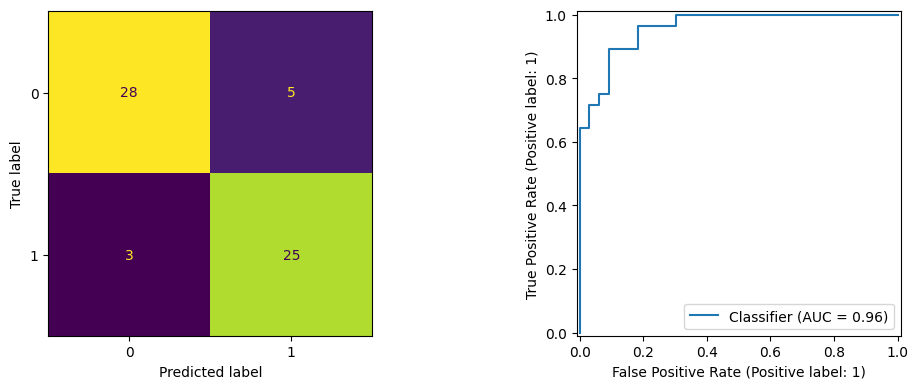

In [8]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
    roc_auc_score,confusion_matrix,classification_report,ConfusionMatrixDisplay,
    RocCurveDisplay)

final_model = clone(best_lr).fit(X_train,y_train)
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:,1]
tn,fp,fn,tp = confusion_matrix(y_test,y_pred,labels=[0,1]).ravel()
final_metrics = {
    'Accuracy':accuracy_score(y_test,y_pred),
    'Precision':precision_score(y_test,y_pred,zero_division=0),
    'Recall (Sensitivity)':recall_score(y_test,y_pred,zero_division=0),
    'Specificity':tn/(tn+fp),
    'F1-score':f1_score(y_test,y_pred,zero_division=0),
    'ROC-AUC':roc_auc_score(y_test,y_prob)
}
print('Confusion counts:', {'TN':tn,'FP':fp,'FN':fn,'TP':tp})
display(pd.DataFrame(final_metrics.items(),columns=['Metric','Value']).round(4))
print(classification_report(y_test,y_pred,digits=4))
fig,axs=plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,ax=axs[0],colorbar=False)
RocCurveDisplay.from_predictions(y_test,y_prob,ax=axs[1])
plt.tight_layout(); plt.show()

## 8. 95% confidence intervals
Wilson score intervals quantify uncertainty for binomial proportions. Stratified bootstrap resampling (5,000 draws) approximates uncertainty in ROC-AUC while retaining the observed class counts. These are sampling-based estimates and do not account for dataset shift or model-selection uncertainty.

### What this code does
Calculate 95% Wilson intervals for classification proportions and a stratified bootstrap interval for ROC-AUC.

,Metric,Estimate,CI Lower,CI Upper,Method
0,Accuracy,0.8689,0.7620,0.9320,Wilson
1,Precision,0.8333,0.6644,0.9266,Wilson
2,Recall (Sensitivity),0.8929,0.7280,0.9629,Wilson
3,Specificity,0.8485,0.6908,0.9335,Wilson
4,ROC-AUC,0.9589,0.9113,0.9913,Stratified bootstrap


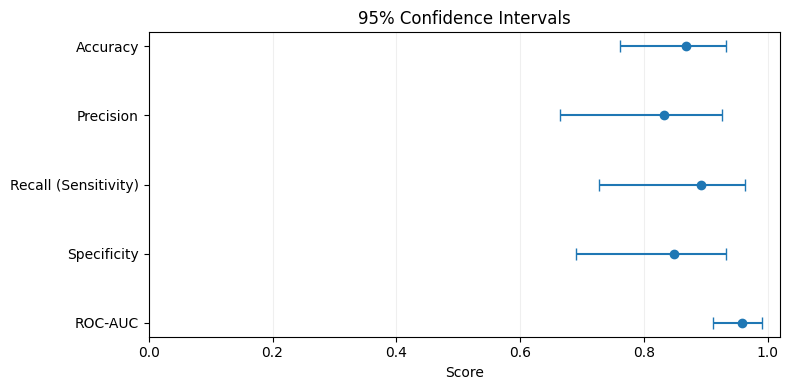

In [9]:
from statsmodels.stats.proportion import proportion_confint
counts = {
    'Accuracy':(tp+tn,len(y_test)),
    'Precision':(tp,tp+fp),
    'Recall (Sensitivity)':(tp,tp+fn),
    'Specificity':(tn,tn+fp)
}
ci_rows=[]
for metric,(success,total) in counts.items():
    low,high=proportion_confint(success,total,alpha=.05,method='wilson')
    ci_rows.append({'Metric':metric,'Estimate':success/total,'CI Lower':low,
                    'CI Upper':high,'Method':'Wilson'})
rng=np.random.default_rng(SEED)
y_true=np.asarray(y_test)
y_scores=np.asarray(y_prob)
pos=np.flatnonzero(y_true==1); neg=np.flatnonzero(y_true==0)
boot_aucs=[]
for _ in range(5000):
    idx=np.concatenate([rng.choice(pos,len(pos),replace=True),
                        rng.choice(neg,len(neg),replace=True)])
    boot_aucs.append(roc_auc_score(y_true[idx],y_scores[idx]))
lo,hi=np.percentile(boot_aucs,[2.5,97.5])
ci_rows.append({'Metric':'ROC-AUC','Estimate':roc_auc_score(y_true,y_scores),
                'CI Lower':lo,'CI Upper':hi,'Method':'Stratified bootstrap'})
confidence_results=pd.DataFrame(ci_rows)
display(confidence_results.round(4))
fig,ax=plt.subplots(figsize=(8,4))
point=confidence_results['Estimate'].to_numpy()
low=confidence_results['CI Lower'].to_numpy()
high=confidence_results['CI Upper'].to_numpy()
ax.errorbar(point,np.arange(len(point)),xerr=[point-low,high-point],fmt='o',capsize=4)
ax.set_yticks(np.arange(len(point)),confidence_results['Metric'])
ax.invert_yaxis();ax.set_xlim(0,1.02);ax.set_xlabel('Score');ax.set_title('95% Confidence Intervals')
ax.grid(axis='x',alpha=.2);plt.tight_layout();plt.show()

## 9. Probability calibration
A high ROC-AUC does not guarantee calibrated probabilities. The Brier score and log loss evaluate probabilistic predictions; a five-bin quantile reliability diagram provides a descriptive calibration check. **Do not recalibrate using the held-out test set.** The reference Brier score below uses test prevalence and is therefore descriptive, not a prospective deployment baseline.

### What this code does
Evaluate probability calibration using Brier score, log loss, and a calibration curve.

,Metric,Value
0,Brier Score,0.0833
1,Log Loss,0.2722
2,Reference Brier Score,0.2483
3,Test Positive Prevalence,0.4590


,Mean Predicted Probability,Observed Positive Fraction
0,0.0332,0.0000
1,0.1613,0.0833
2,0.5056,0.5000
3,0.8445,0.7500
4,0.9695,1.0000


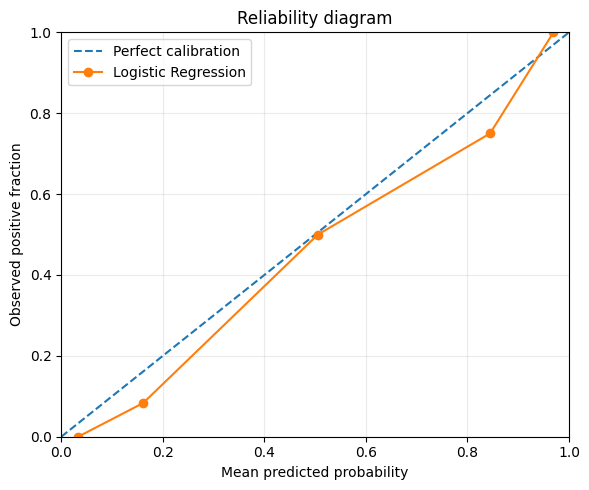

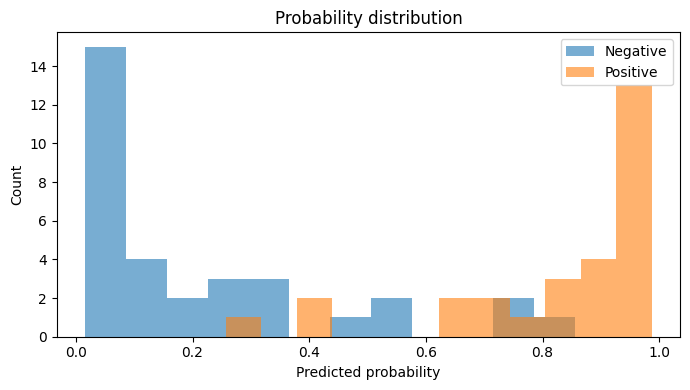

In [10]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss
frac_pos,mean_prob=calibration_curve(y_true,y_scores,n_bins=5,strategy='quantile')
brier=brier_score_loss(y_true,y_scores)
logloss=log_loss(y_true,y_scores,labels=[0,1])
prevalence=y_true.mean()
ref_brier=brier_score_loss(y_true,np.full(len(y_true),prevalence))
calibration_metrics=pd.DataFrame({'Metric':['Brier Score','Log Loss','Reference Brier Score','Test Positive Prevalence'],
                                  'Value':[brier,logloss,ref_brier,prevalence]})
calibration_table=pd.DataFrame({'Mean Predicted Probability':mean_prob,
                                'Observed Positive Fraction':frac_pos})
display(calibration_metrics.round(4));display(calibration_table.round(4))
fig,ax=plt.subplots(figsize=(6,5))
ax.plot([0,1],[0,1],'--',label='Perfect calibration')
ax.plot(mean_prob,frac_pos,'o-',label='Logistic Regression')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',
       ylabel='Observed positive fraction',title='Reliability diagram')
ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(7,4))
ax.hist(y_scores[y_true==0],bins=12,alpha=.6,label='Negative')
ax.hist(y_scores[y_true==1],bins=12,alpha=.6,label='Positive')
ax.set(xlabel='Predicted probability',ylabel='Count',title='Probability distribution')
ax.legend();plt.tight_layout();plt.show()

## 10. Exploratory repeated-CV model comparison
Three fixed configurations are compared on identical 5×10 validation folds, entirely within the training set. The corrected repeated-CV t-test uses an approximate dependence correction; Holm-adjusted p-values control multiple pairwise comparisons. These tests are exploratory, not proof of equivalence or superiority. Random Forest and SVM configurations are fixed here and may differ from historical experiments.

### What this code does
Compare fixed model configurations on identical repeated-CV splits and use exploratory corrected statistical tests.

,Mean_AUC,SD_AUC,Mean_Accuracy,SD_Accuracy
Model,,,,
Random Forest,0.8960,0.0356,0.8020,0.0448
Logistic Regression,0.8931,0.0365,0.8185,0.0458
SVM,0.8829,0.0382,0.8090,0.0461


,Model A,Model B,Mean AUC Difference,Corrected t,Raw p-value,Holm p-value
0,Logistic Regression,Random Forest,-0.00287,-0.24432,0.80800,0.80800
1,Logistic Regression,SVM,0.01018,1.21533,0.23007,0.46013
2,Random Forest,SVM,0.01305,1.61200,0.11338,0.34015


/tmp/ipykernel_2960/644147551.py:54: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([cv_results.loc[cv_results.Model==name,'ROC-AUC'].to_numpy()


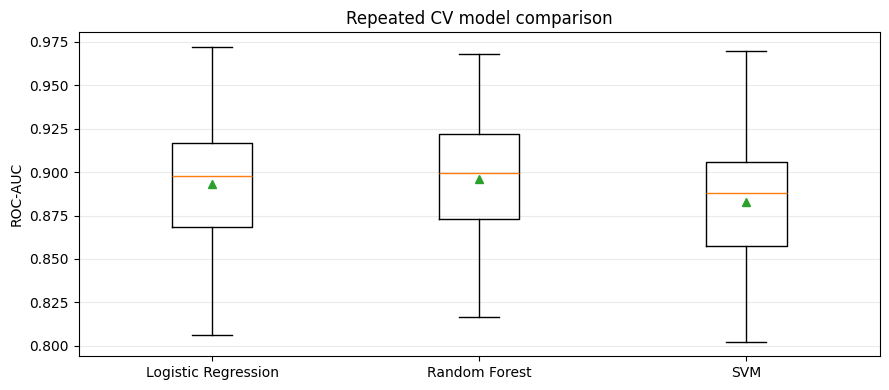

In [11]:
from scipy.stats import t as student_t
from itertools import combinations
from statsmodels.stats.multitest import multipletests

models={
    'Logistic Regression':clone(best_lr),
    'Random Forest':Pipeline([('preprocessor',clone(preprocessor)),
        ('classifier',RandomForestClassifier(n_estimators=500,min_samples_leaf=2,
                                           random_state=SEED,n_jobs=-1))]),
    'SVM':Pipeline([('preprocessor',clone(preprocessor)),
        ('classifier',SVC(kernel='rbf',C=1.0))])
}
def rows(obj,idx):
    return obj.iloc[idx] if hasattr(obj,'iloc') else np.asarray(obj)[idx]
records=[]
for fold,(tri,vi) in enumerate(repeated_cv.split(X_train,y_train),1):
    xtr,xval=rows(X_train,tri),rows(X_train,vi)
    ytr,yval=rows(y_train,tri),rows(y_train,vi)
    for name,estimator in models.items():
        fitted=clone(estimator).fit(xtr,ytr)
        pred=fitted.predict(xval)
        scores=(fitted.predict_proba(xval)[:,1] if hasattr(fitted,'predict_proba')
                else fitted.decision_function(xval))
        records.append({'Fold':fold,'Model':name,'ROC-AUC':roc_auc_score(yval,scores),
                        'Accuracy':accuracy_score(yval,pred),
                        'Train Size':len(tri),'Validation Size':len(vi)})
cv_results=pd.DataFrame(records)
summary=cv_results.groupby('Model').agg(Mean_AUC=('ROC-AUC','mean'),
    SD_AUC=('ROC-AUC','std'),Mean_Accuracy=('Accuracy','mean'),
    SD_Accuracy=('Accuracy','std')).sort_values('Mean_AUC',ascending=False)
display(summary.round(4))
wide=cv_results.pivot(index='Fold',columns='Model',values='ROC-AUC')
# Fold sizes differ by at most one; use mean validation/training ratio.
ratio=np.mean(cv_results.drop_duplicates('Fold')['Validation Size']/
              cv_results.drop_duplicates('Fold')['Train Size'])
correction=1/len(wide)+ratio
comparisons=[]
for a,b in combinations(wide.columns,2):
    d=(wide[a]-wide[b]).to_numpy(); mean=d.mean(); var=d.var(ddof=1)
    se=np.sqrt(correction*var)
    stat=mean/se if se>0 else np.nan
    p=2*student_t.sf(abs(stat),df=len(d)-1) if se>0 else (1.0 if mean==0 else np.nan)
    comparisons.append({'Model A':a,'Model B':b,'Mean AUC Difference':mean,
                        'Corrected t':stat,'Raw p-value':p})
comparison_df=pd.DataFrame(comparisons)
valid=comparison_df['Raw p-value'].notna()
comparison_df['Holm p-value']=np.nan
if valid.any():
    comparison_df.loc[valid,'Holm p-value']=multipletests(
        comparison_df.loc[valid,'Raw p-value'],method='holm')[1]
display(comparison_df.round(5))
fig,ax=plt.subplots(figsize=(9,4))
labels=list(models)
ax.boxplot([cv_results.loc[cv_results.Model==name,'ROC-AUC'].to_numpy()
            for name in labels],labels=labels,showmeans=True)
ax.set(ylabel='ROC-AUC',title='Repeated CV model comparison');ax.grid(axis='y',alpha=.25)
plt.tight_layout();plt.show()

## 11. Permutation feature importance
Permutation importance is estimated using training-only validation folds, **not the held-out test set**. The analysis below uses a single stratified training/validation split for exploratory interpretation; importance scores are not causal effects and may be unstable for correlated predictors.

### What this code does
Estimate permutation feature importance using training-only validation data. A larger ROC-AUC drop indicates greater predictive reliance.

,Feature,Mean AUC Decrease,SD
11,ca,0.0718,0.0203
2,cp,0.0529,0.0137
1,sex,0.0362,0.0143
12,thal,0.0333,0.0171
10,slope,0.0077,0.0119
7,thalach,0.0065,0.0065
8,exang,0.0037,0.0034
9,oldpeak,0.0014,0.0039
6,restecg,0.0009,0.0013
5,fbs,0.0000,0.0000


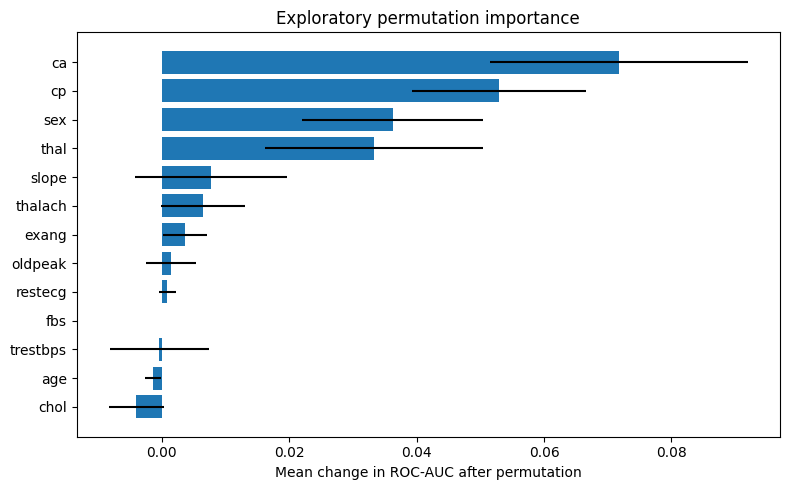

In [12]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
x_fit,x_val,y_fit,y_val=train_test_split(X_train,y_train,test_size=.25,
                                        random_state=SEED,stratify=y_train)
interpret_model=clone(best_lr).fit(x_fit,y_fit)
perm=permutation_importance(interpret_model,x_val,y_val,n_repeats=30,
                            random_state=SEED,scoring='roc_auc',n_jobs=-1)
importance=pd.DataFrame({'Feature':X_train.columns,
                         'Mean AUC Decrease':perm.importances_mean,
                         'SD':perm.importances_std}).sort_values('Mean AUC Decrease',ascending=False)
display(importance.round(4))
fig,ax=plt.subplots(figsize=(8,5))
top=importance.head(13).iloc[::-1]
ax.barh(top['Feature'],top['Mean AUC Decrease'],xerr=top['SD'])
ax.set(xlabel='Mean change in ROC-AUC after permutation',
       title='Exploratory permutation importance')
plt.tight_layout();plt.show()

## 12. Literature context and critical discussion
**Dataset reference:** Janosi, A., Steinbrunn, W., Pfisterer, M., and Detrano, R. *Heart Disease*. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X

**Foundational publication:** Detrano, R., et al. (1989). *International application of a new probability algorithm for the diagnosis of coronary artery disease*. American Journal of Cardiology, 64(5), 304–310. https://doi.org/10.1016/0002-9149(89)90524-9

**Comparison rule:** Do not rank this notebook against published accuracy or AUC numbers unless target definition, row inclusion, predictor availability, cross-validation design, hyperparameter search and hold-out methodology are verified. A literature review with exact quoted metrics should be added only after checking the original papers.

### Discussion
- The Cleveland benchmark contains only 303 observations, so split-to-split variation is consequential.
- Repeated CV summarizes variation across training folds, but it does not create independent patients.
- A high test AUC does not establish clinical generalizability.
- Calibration assessment on 61 observations is exploratory.
- Corrected repeated-CV significance tests are approximate and sensitive to protocol choices.
- Model performance should be validated externally on independently collected patient data before any clinical use.

### Conclusion
This notebook demonstrates a leakage-aware and reproducible workflow for evaluating structured heart-disease classifiers. Its principal contribution is methodological transparency: discrimination, classification, uncertainty, calibration, statistical comparison, and interpretation are reported together, with explicit limits on what the evidence can establish.

## 13. Export results and fitted model
All tables and the final fitted pipeline are exported for archival use. The model artifact is **research-only**. Only load serialized models from trusted sources because Python pickle/joblib deserialization can execute code.

### What this code does
Export result tables and the fitted model. Check the output folder for saved files.

In [13]:
import joblib
benchmark_df.to_csv(OUTPUT_DIR/'benchmark.csv',index=False)
cv_summary.to_csv(OUTPUT_DIR/'logistic_repeated_cv.csv',index=False)
pd.DataFrame(final_metrics.items(),columns=['Metric','Value']).to_csv(
    OUTPUT_DIR/'final_test_metrics.csv',index=False)
confidence_results.to_csv(OUTPUT_DIR/'confidence_intervals.csv',index=False)
calibration_metrics.to_csv(OUTPUT_DIR/'calibration_metrics.csv',index=False)
calibration_table.to_csv(OUTPUT_DIR/'calibration_table.csv',index=False)
summary.to_csv(OUTPUT_DIR/'model_comparison_summary.csv')
comparison_df.to_csv(OUTPUT_DIR/'statistical_comparisons.csv',index=False)
importance.to_csv(OUTPUT_DIR/'permutation_importance.csv',index=False)
joblib.dump(final_model,OUTPUT_DIR/'cleveland_logistic_pipeline.joblib')
with open(OUTPUT_DIR/'environment.txt','w') as f:
    f.write(f'Python {sys.version}\nscikit-learn {sklearn.__version__}\n'
            f'pandas {pd.__version__}\nnumpy {np.__version__}\n'
            f'scipy {scipy.__version__}\nstatsmodels {statsmodels.__version__}\n')
import shutil
archive=shutil.make_archive('cleveland_research_outputs','zip',OUTPUT_DIR)
print('Exported:',archive)
print('Notebook execution complete. Review all results before publication.')

Exported: /content/cleveland_research_outputs.zip
Notebook execution complete. Review all results before publication.


# 14. Feature Engineering Ablation Study

**Question:** Do four predefined derived features improve Logistic Regression compared with the original 13 features?

- **Baseline:** Original 13 features with the established preprocessing pipeline.
- **Engineered:** Original features plus `age_squared`, `age_x_thalach`, `oldpeak_x_slope`, and `cp_x_exang`.
- **Evaluation:** Identical repeated stratified 5-fold CV splits (10 repeats) on the training set only.
- **Fair comparison:** Keep the previously selected classifier settings unchanged. Fit all preprocessing inside each training fold.

**Caution:** Some categorical feature codes are numerical labels, not continuous measurements. Interactions involving these codes are exploratory and should not be interpreted clinically. The held-out test set is not used to choose features.

In [14]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class AddHeartFeatures(BaseEstimator, TransformerMixin):
    """Add derived features without fitting on validation data."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        z = X.copy()
        z['age_squared'] = z['age'] ** 2
        z['age_x_thalach'] = z['age'] * z['thalach']
        z['oldpeak_x_slope'] = z['oldpeak'] * z['slope']
        z['cp_x_exang'] = z['cp'] * z['exang']
        return z

engineered_names = ['age_squared','age_x_thalach','oldpeak_x_slope','cp_x_exang']
engineered_preprocessor = ColumnTransformer([
    ('numeric', clone(numeric_transformer), numeric_features + engineered_names),
    ('categorical', clone(categorical_transformer), categorical_features)
])

# Reuse the classifier configuration selected from training data.
lr_params = best_lr.named_steps['classifier'].get_params()
baseline_model = clone(best_lr)
engineered_model = Pipeline([
    ('feature_engineering', AddHeartFeatures()),
    ('preprocessor', engineered_preprocessor),
    ('classifier', clone(best_lr.named_steps['classifier']))
])

print('Baseline: 13 original features')
print('Engineered: 13 original + 4 derived features')
print('Classifier penalty:', lr_params['penalty'], '| C:', lr_params['C'])
print('Final test set remains untouched.')

Baseline: 13 original features
Engineered: 13 original + 4 derived features
Classifier penalty: l1 | C: 1.0
Final test set remains untouched.


## Run the comparison

Train and evaluate both pipelines on the **same folds**. Imputation and scaling are learned from each training fold only, preventing validation-data leakage. This is an exploratory comparison, not a new independent test.

In [15]:
cv_fe = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
fe_rows = []
for fold_id, (train_idx, valid_idx) in enumerate(cv_fe.split(X_train, y_train), start=1):
    Xtr, Xva = X_train.iloc[train_idx], X_train.iloc[valid_idx]
    ytr, yva = y_train.iloc[train_idx], y_train.iloc[valid_idx]
    for label, estimator in [('Baseline', baseline_model), ('Engineered', engineered_model)]:
        fitted = clone(estimator).fit(Xtr, ytr)
        probs = fitted.predict_proba(Xva)[:, 1]
        preds = fitted.predict(Xva)
        fe_rows.append({
            'Fold': fold_id, 'Model': label,
            'ROC-AUC': roc_auc_score(yva, probs),
            'Accuracy': accuracy_score(yva, preds),
            'Train Size': len(train_idx), 'Validation Size': len(valid_idx)
        })

fe_results = pd.DataFrame(fe_rows)
fe_summary = fe_results.groupby('Model').agg(
    Mean_AUC=('ROC-AUC', 'mean'),
    SD_AUC=('ROC-AUC', 'std'),
    Mean_Accuracy=('Accuracy', 'mean'),
    SD_Accuracy=('Accuracy', 'std')
)
display(fe_summary.round(4))

paired_auc = fe_results.pivot(index='Fold', columns='Model', values='ROC-AUC')
paired_acc = fe_results.pivot(index='Fold', columns='Model', values='Accuracy')
auc_diff = paired_auc['Engineered'] - paired_auc['Baseline']
acc_diff = paired_acc['Engineered'] - paired_acc['Baseline']
print(f'Mean paired ROC-AUC difference (Engineered - Baseline): {auc_diff.mean():+.4f}')
print(f'Mean paired Accuracy difference (Engineered - Baseline): {acc_diff.mean():+.4f}')
print(f'Engineered higher AUC in {(auc_diff > 0).sum()} / {len(auc_diff)} folds; '
      f'equal in {(auc_diff == 0).sum()} folds')

,Mean_AUC,SD_AUC,Mean_Accuracy,SD_Accuracy
Model,,,,
Baseline,0.8931,0.0365,0.8185,0.0458
Engineered,0.8926,0.0377,0.8202,0.0496


Mean paired ROC-AUC difference (Engineered - Baseline): -0.0005
Mean paired Accuracy difference (Engineered - Baseline): +0.0016
Engineered higher AUC in 19 / 50 folds; equal in 5 folds


## Visualize and interpret the results

- A **positive paired ROC-AUC difference** favors the engineered model; a negative value favors the baseline.
- Compare the mean and spread of scores across folds, not only the best fold.
- Boxplot overlap alone does not establish statistical significance.
- The corrected repeated-CV t-test is **exploratory** because repeated folds are dependent.
- Do not use the held-out test set to select features.

Corrected repeated-CV t statistic: -0.1646
Exploratory two-sided p-value: 0.86994
Interpretation: No statistically significant difference detected


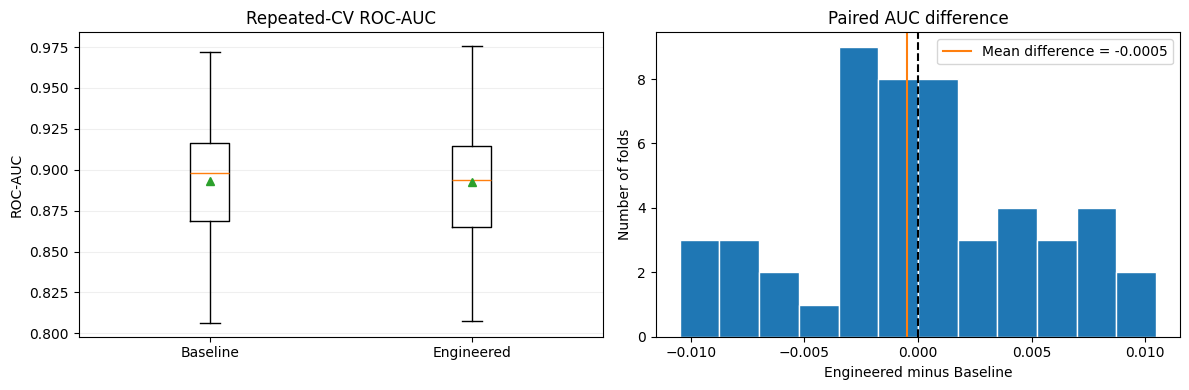

Saved feature-engineering tables in: cleveland_outputs


In [16]:
from scipy.stats import t as student_t
ratio = np.mean(
    fe_results.drop_duplicates('Fold')['Validation Size'] /
    fe_results.drop_duplicates('Fold')['Train Size']
)
d = auc_diff.to_numpy()
n = len(d)
corrected_se = np.sqrt((1/n + ratio) * np.var(d, ddof=1))
if corrected_se > 0:
    corrected_t = np.mean(d) / corrected_se
    corrected_p = 2 * student_t.sf(abs(corrected_t), df=n-1)
else:
    corrected_t = np.nan
    corrected_p = 1.0 if np.mean(d) == 0 else np.nan
print('Corrected repeated-CV t statistic:', round(corrected_t, 4))
print('Exploratory two-sided p-value:', round(corrected_p, 5))
print('Interpretation:', 'Evidence of a difference at alpha=0.05 (exploratory)'
      if corrected_p < 0.05 else 'No statistically significant difference detected')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(
    [paired_auc['Baseline'].to_numpy(), paired_auc['Engineered'].to_numpy()],
    tick_labels=['Baseline','Engineered'], showmeans=True
)
axes[0].set(title='Repeated-CV ROC-AUC', ylabel='ROC-AUC')
axes[0].grid(axis='y', alpha=0.2)
axes[1].hist(d, bins=12, edgecolor='white')
axes[1].axvline(0, linestyle='--', color='black')
axes[1].axvline(d.mean(), linestyle='-', color='tab:orange',
                label=f'Mean difference = {d.mean():+.4f}')
axes[1].set(title='Paired AUC difference', xlabel='Engineered minus Baseline',
            ylabel='Number of folds')
axes[1].legend()
plt.tight_layout()
plt.show()

fe_results.to_csv(OUTPUT_DIR/'feature_engineering_cv_folds.csv', index=False)
fe_summary.to_csv(OUTPUT_DIR/'feature_engineering_summary.csv')
pd.DataFrame({'Fold': paired_auc.index, 'AUC_difference': d,
              'Accuracy_difference': acc_diff.to_numpy()}).to_csv(
                  OUTPUT_DIR/'feature_engineering_paired_differences.csv', index=False)
print('Saved feature-engineering tables in:', OUTPUT_DIR)

## Feature Engineering Results and Interpretation

An exploratory feature-engineering ablation study compared the original 13-feature Logistic Regression pipeline with a pipeline containing four predefined derived features. Both models were evaluated using identical repeated stratified five-fold cross-validation splits (10 repeats) on the training data only.

Mean ROC-AUC was **0.8931** for the baseline and **0.8926** for the engineered model (mean paired difference **−0.0005**; exploratory corrected p-value **0.86994**). The engineered model showed a small numerical increase in mean accuracy (0.8185 to 0.8202), but no clear improvement in ROC-AUC.

These results **did not demonstrate an improvement** from the four tested engineered features under this evaluation protocol. Retaining the original 13-feature representation is a reasonable, simpler choice for this analysis.

**Interpretation note:** A non-significant result does not prove equivalence, and it does not rule out benefits from other feature-engineering approaches. Independent external validation remains necessary.
